In [2]:
import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

In [3]:
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub. load (MODEL_URL)

In [13]:
COCO_CLASSES = ["person", "bicycle", "car", "motorcycle", "airplane", "bus",
"train", "truck", "boat", "traffic light", "fire hydrant", "stop sign",
"parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
# ... (80 names in total) ...
"scissors", "teddy bear", "hair drier", "toothbrush"]

def detect_objects_with_boxes(image_path, detector):

  image = cv2.imread(image_path)
  orig_image = image.copy()

  input_tensor = tf.convert_to_tensor(image)
  input_tensor = input_tensor[tf.newaxis, ... ]

  detections = detector(input_tensor)

  num_detections= int(detections["num_detections"])
  detection_boxes= detections["detection_boxes"].numpy () [0]
  detection_classes = detections["detection_classes"].numpy() [0] .astype(np.int32)
  detection_scores = detections["detection_scores"].numpy() [0]


  confidence_threshold = 0.5
  for i in range(num_detections):
    score = detection_scores [i]
    if score > confidence_threshold:
      box = detection_boxes [i]
      h, w, _ = orig_image.shape
      y_min, x_min, y_max, x_max = box
      x_min, x_max = int(x_min * w), int(x_max * w)
      y_min, y_max = int(y_min * h), int(y_max * h)
      class_id = detection_classes[i]
      class_name = COCO_CLASSES[class_id - 1] if 1 <= class_id <= 80 else "Unknown"
      label = f"{class_name}: {score :.2f}"
      cv2.rectangle(orig_image, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
      cv2.putText(orig_image, label, (x_min, y_min - 10),
      cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255, 0), 2)


  return orig_image


Saving traffic.jpg to traffic (6).jpg


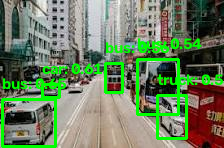

In [16]:
uploaded = files.upload()
image_path = next(iter(uploaded))
result_image = detect_objects_with_boxes(image_path, detector)
cv2_imshow(result_image)